Name : Mohammad Ayaan Khan

USC ID : 4147952900

Email : mkhan736@usc.edu

GitHub username : MohammadAyaanKhan

# Homework 6: Tree-Based Methods, Class Imbalance and SMOTE

**Dataset:** APS Failure at Scania Trucks (https://archive.ics.uci.edu/dataset/421/aps+failure+at+scania+trucks),
stored in `../data/` and downloaded from UCI automatically if missing. Problems 2 to 5 (ISLR exercises) are
answered at the end of the notebook.

All random processes use the seed 552 so the results are reproducible. SMOTE and the cross-validated XGBoost
searches are slow; the whole notebook takes roughly 15 to 25 minutes to run.

In [ ]:
# Imports
import os, io, gzip, zipfile, urllib.request, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_validate
from sklearn.metrics import confusion_matrix, roc_auc_score, roc_curve
from imblearn.ensemble import BalancedRandomForestClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
import xgboost as xgb

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.width', 140)
sns.set_theme(style='whitegrid')
SEED = 552
DATA_DIR = '../data'
os.makedirs(DATA_DIR, exist_ok=True)

def fetch_uci(zip_url, members):
    # Download a UCI zip once and save the files we need into DATA_DIR. CSV files are stored gzip-compressed
    # (e.g. aps_failure_training_set.csv.gz) so each fits under GitHub's 25 MB upload limit.
    targets = {m: m + '.gz' if m.endswith('.csv') else m for m in members}
    if all(os.path.exists(os.path.join(DATA_DIR, t)) for t in targets.values()):
        return
    z = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(zip_url).read()))
    for m, t in targets.items():
        opener = gzip.open if t.endswith('.gz') else open
        with opener(os.path.join(DATA_DIR, t), 'wb') as f:
            f.write(z.read(m))

def evaluate(name, model, X_tr, y_tr, X_te, y_te):
    # Confusion matrix, AUC and misclassification rate on the training and test sets, plus both ROC curves
    out = {}
    fig, ax = plt.subplots(figsize=(5.5, 4.5))
    for split, X_, y_ in [('train', X_tr, y_tr), ('test', X_te, y_te)]:
        prob = model.predict_proba(X_)[:, 1]
        pred = (prob >= 0.5).astype(int)
        cm = confusion_matrix(y_, pred, labels=[0, 1])
        auc = roc_auc_score(y_, prob)
        err = (pred != y_).mean()
        fpr, tpr, _ = roc_curve(y_, prob)
        ax.plot(fpr, tpr, label=f'{split} (AUC = {auc:.4f})')
        out[split] = {'cm': cm, 'auc': auc, 'err': err}
        print(f'{name} | {split}: AUC = {auc:.4f}   misclassification = {err:.5f}')
        print(pd.DataFrame(cm, index=['true neg', 'true pos'], columns=['pred neg', 'pred pos']).to_string(), '\n')
    ax.plot([0, 1], [0, 1], 'k:', lw=1)
    ax.set_xlabel('False positive rate'); ax.set_ylabel('True positive rate')
    ax.set_title(f'ROC curves: {name}'); ax.legend(loc='lower right')
    plt.show()
    return out

summary = {} # summary: test AUC, test error and positives caught for every model, for the final table
print('xgboost', xgb.__version__)

xgboost 3.4.1


# 1. Tree-Based Methods

## 1(a) Download the APS Failure data

In [ ]:
fetch_uci('https://archive.ics.uci.edu/static/public/421/aps+failure+at+scania+trucks.zip',
          ['aps_failure_training_set.csv', 'aps_failure_test_set.csv', 'aps_failure_description.txt'])

# Each CSV is gzip-compressed (pandas decompresses .gz files automatically), starts with a 20-line licence header, and codes missing values as 'na'
train = pd.read_csv(os.path.join(DATA_DIR, 'aps_failure_training_set.csv.gz'), skiprows=20, na_values='na')
test = pd.read_csv(os.path.join(DATA_DIR, 'aps_failure_test_set.csv.gz'), skiprows=20, na_values='na')

features = [c for c in train.columns if c != 'class']# features: the 170 numeric attributes
X_train_raw, X_test_raw = train[features], test[features]
y_train = (train['class'] == 'pos').astype(int).values # 1 = APS component failure, 0 = other failure
y_test = (test['class'] == 'pos').astype(int).values
print('Training set:', train.shape, ' Test set:', test.shape)
print('Number of features:', len(features))
train.head()

Training set: (60000, 171)  Test set: (16000, 171)
Number of features: 170


,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,...,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,neg,76698,NaN,2.130706e+09,280.0,0.0,0.0,0.0,0.0,0.0,...,1240520.0,493384.0,721044.0,469792.0,339156.0,157956.0,73224.0,0.0,0.0,0.0
1,neg,33058,NaN,0.000000e+00,NaN,0.0,0.0,0.0,0.0,0.0,...,421400.0,178064.0,293306.0,245416.0,133654.0,81140.0,97576.0,1500.0,0.0,0.0
2,neg,41040,NaN,2.280000e+02,100.0,0.0,0.0,0.0,0.0,0.0,...,277378.0,159812.0,423992.0,409564.0,320746.0,158022.0,95128.0,514.0,0.0,0.0
3,neg,12,0.0,7.000000e+01,66.0,0.0,10.0,0.0,0.0,0.0,...,240.0,46.0,58.0,44.0,10.0,0.0,0.0,0.0,4.0,32.0
4,neg,60874,NaN,1.368000e+03,458.0,0.0,0.0,0.0,0.0,0.0,...,622012.0,229790.0,405298.0,347188.0,286954.0,311560.0,433954.0,1218.0,0.0,0.0


**Data.** Each row is a heavy Scania truck. The positive class (`pos`) is a failure of a specific component of the
Air Pressure System (APS), which supplies pressurised air for braking and gear changes; the negative class (`neg`)
is a failure of a component not related to the APS. The 170 attributes are anonymised operational readings (for
example `aa_000`); names sharing a prefix with different suffixes (such as `ag_000` to `ag_009`) are bins of the
same histogram. The training set has 60,000 rows and the test set 16,000.

**Cost of mistakes.** The data description defines a misclassification cost: a false alarm (a truck predicted to
have an APS failure that does not) costs 10, because a mechanic checks it unnecessarily, and a missed failure costs
500, because the truck may break down. Total cost = 10 × false alarms + 500 × missed failures. Because a missed
failure is 50 times as costly as a false alarm, the total cost is reported alongside the error rate below.

## 1(b) Data preparation

### 1(b)(i) Missing values: techniques and the one applied

In [ ]:
miss_frac = X_train_raw.isna().mean()# miss_frac: share of missing values in each feature
print('Features with missing values:', int((miss_frac > 0).sum()), 'of', len(features))
print('Training rows with at least one missing value:', f'{X_train_raw.isna().any(axis=1).mean():.1%}')
print('Features missing in more than 50% of rows:', int((miss_frac > 0.5).sum()))
print('Highest missing share:', miss_frac.idxmax(), f'{miss_frac.max():.1%}')

Features with missing values: 169 of 170
Training rows with at least one missing value: 99.0%
Features missing in more than 50% of rows: 8
Highest missing share: br_000 82.1%


**Techniques for missing values** (data imputation):
- **Deletion:** drop rows with any missing value (listwise deletion) or drop features with many missing values. This is only safe when few values are missing; here 99% of the training rows have at least one missing value, so listwise deletion would discard almost all of the data.
- **Simple statistics:** replace each missing value with the feature's mean, median or most frequent value. Fast and easy, but it ignores relationships between features and shrinks the feature's variance.
- **Constant plus indicator:** fill with a constant and add a binary column flagging that the value was missing, so the model can learn from the missingness itself.
- **k-nearest-neighbour imputation:** fill a value with the average of that feature over the $k$ most similar rows.
- **Model-based (iterative) imputation**, such as MICE: model each feature with missing values as a function of the others, and repeat until the imputed values stabilise. Usually the most accurate, but slow on 60,000 rows and 170 features.
- **Models that handle missing values natively:** for example, XGBoost learns a default direction for missing values at each split.

**Method applied: median imputation.** The features are non-negative counts and histogram bins with extremely skewed distributions, so the median is much more robust than the mean, and it is fast enough for the large data set. Following footnote 1, the training set is imputed with training-set medians, and the test set is imputed with its own test-set medians, so no training statistics are used on the test data. The same imputed data is used for every model below, including XGBoost, so that the models are compared on identical inputs (SMOTE also requires complete data).

In [ ]:
# Median imputation. Training data is imputed with training medians and, as footnote 1 asks, the test data is imputed with its own (test) medians.
X_train = pd.DataFrame(SimpleImputer(strategy='median').fit_transform(X_train_raw), columns=features)
X_test = pd.DataFrame(SimpleImputer(strategy='median').fit_transform(X_test_raw), columns=features)
print('Missing values after imputation: train =', int(X_train.isna().sum().sum()), ' test =', int(X_test.isna().sum().sum()))

Missing values after imputation: train = 0  test = 0


### 1(b)(ii) Coefficient of variation of each feature

The coefficient of variation $CV = s/m$ measures a feature's spread relative to its mean. It is unitless, so the
170 features, which are on very different scales, can be compared directly. It is computed on the imputed
training set.

In [ ]:
cv_table = pd.DataFrame({'mean': X_train.mean(), 'std': X_train.std(ddof=1)})
cv_table['CV'] = cv_table['std'] / cv_table['mean']
cv_table['CV'] = cv_table['CV'].fillna(0) # cd_000 is constant (std = 0, mean > 0), so its CV is 0
cv_table = cv_table.sort_values('CV', ascending=False)

# All 170 features in two side-by-side columns (read down each column) to keep the output short
rows = [f'{f:<9s}{m:12.4g}{s:12.4g}{v:9.3f}' for f, (m, s, v) in cv_table.iterrows()]
half = int(np.ceil(len(rows) / 2))
header = f"{'feature':<9s}{'mean':>12s}{'std':>12s}{'CV':>9s}"
print(header + '     ' + header)
for r in range(half):
    print(rows[r] + ('     ' + rows[r + half] if r + half < len(rows) else ''))

feature          mean         std       CV     feature          mean         std       CV
cf_000      1.431e+05   3.505e+07  244.888     cx_000      2.808e+05   1.334e+06    4.749
co_000      1.433e+05   3.505e+07  244.507     cs_004      4.403e+05   2.063e+06    4.685
ad_000      1.434e+05   3.505e+07  244.323     eb_000       9.11e+06   4.136e+07    4.540
cs_009          770.5   1.833e+05  237.931     de_000          364.7        1651    4.528
dh_000           4393   5.412e+05  123.216     cn_003      5.258e+05   2.204e+06    4.192
dj_000          37.27        4379  117.494     cg_000          80.25         323    4.025
ag_000          219.2   2.036e+04   92.918     ax_000          361.5        1453    4.019
as_000          125.4   1.095e+04   87.332     ay_008       1.04e+06    3.97e+06    3.816
ay_009           1150   9.741e+04   84.734     cs_001          783.6        2871    3.663
ak_000          907.7     7.3e+04   80.425     dv_000      5.682e+05   2.039e+06    3.587
az_009    

### 1(b)(iii) Correlation matrix

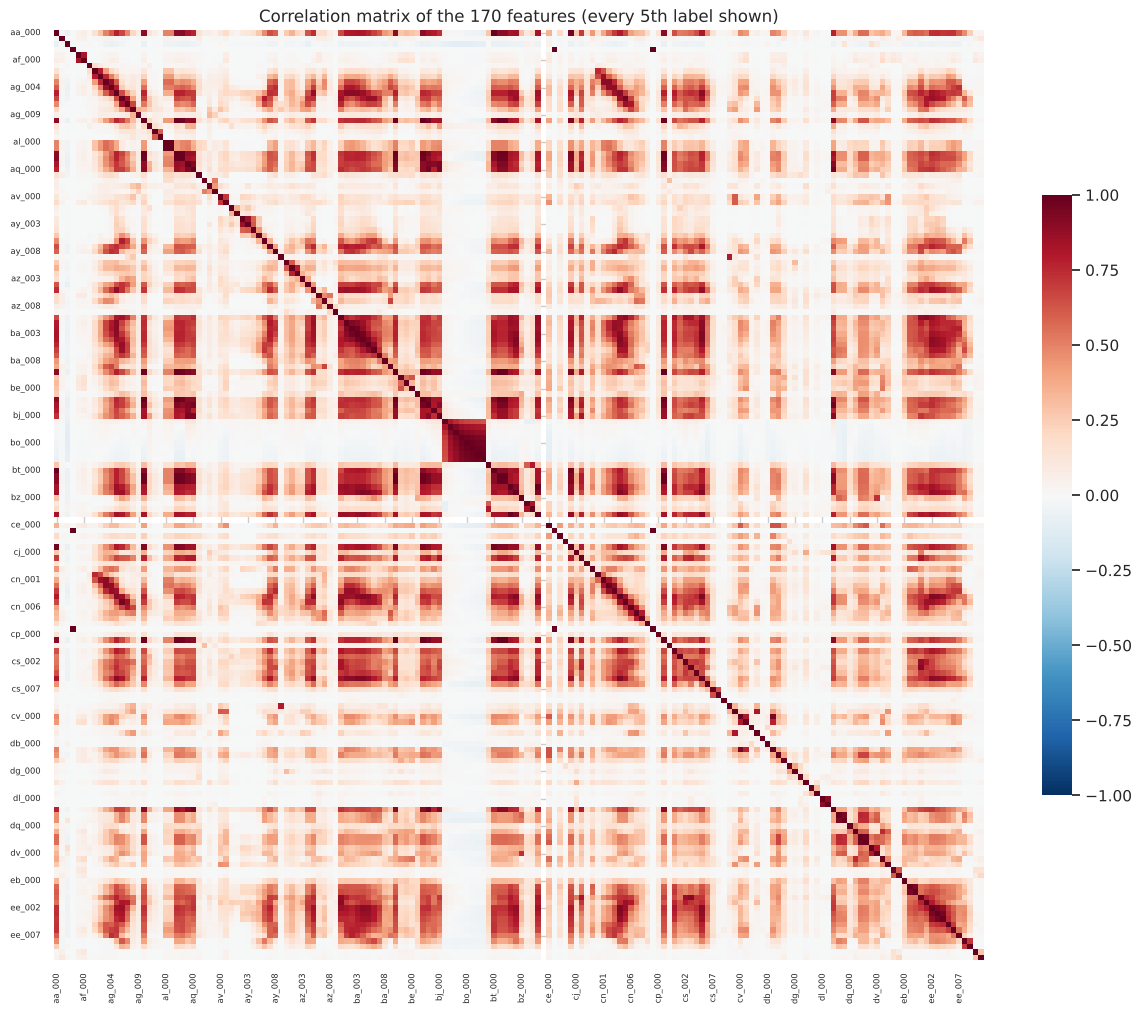

Feature pairs: 14196   with |r| > 0.9: 130   with |r| > 0.7: 772

Top 10 most correlated feature pairs:
bv_000  cq_000    1.000
bu_000  cq_000    1.000
        bv_000    1.000
cf_000  co_000    1.000
ad_000  cf_000    1.000
        co_000    1.000
aa_000  bt_000    0.999
ah_000  bg_000    0.998
bb_000  bv_000    0.996
        bu_000    0.996


In [ ]:
corr = X_train.corr()# corr: 170 x 170 Pearson correlations (cd_000 is constant, so its row and column are empty)
fig, ax = plt.subplots(figsize=(15, 13))
sns.heatmap(corr, cmap='RdBu_r', center=0, vmin=-1, vmax=1, square=True, xticklabels=5, yticklabels=5,
            cbar_kws={'shrink': 0.6}, ax=ax)
ax.tick_params(labelsize=6)
ax.set_title('Correlation matrix of the 170 features (every 5th label shown)')
plt.show()

upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().dropna()   # upper: each feature pair once
print('Feature pairs:', len(upper), '  with |r| > 0.9:', int((upper.abs() > 0.9).sum()),
      '  with |r| > 0.7:', int((upper.abs() > 0.7).sum()))
print('\nTop 10 most correlated feature pairs:')
print(upper.reindex(upper.abs().sort_values(ascending=False).index).head(10).round(3).to_string())

**Reading the correlation matrix.** Many features are strongly correlated: of the 14,196 feature pairs, 772 have $|r| > 0.7$ and 130 have $|r| > 0.9$. Some features are essentially duplicates: `bu_000`, `bv_000` and `cq_000` are perfectly correlated (1.000), as are `ad_000`, `cf_000` and `co_000`, and `aa_000` and `bt_000` (0.999). The large red blocks show groups of features that rise together, such as the bins of the same histogram (for example `ba_000` to `ba_009` and `ee_000` to `ee_009`), which mostly reflect how much a truck has been used. `cd_000` is constant, so its row and column are empty (the white line). Strongly correlated features carry overlapping information; tree-based models handle this well, because they simply split on whichever of the correlated features works best.

### 1(b)(iv) The $\lfloor\sqrt{170}\rfloor$ features with the highest CV: scatter plots and box plots

In [ ]:
k = int(np.floor(np.sqrt(170)))# k: number of features to plot, floor(sqrt(170)) = 13
top_cv = list(cv_table.index[:k])# top_cv: the k features with the highest CV
print(f'floor(sqrt(170)) = {k}')
print('Features with the highest CV:', top_cv)

floor(sqrt(170)) = 13
Features with the highest CV: ['cf_000', 'co_000', 'ad_000', 'cs_009', 'dh_000', 'dj_000', 'ag_000', 'as_000', 'ay_009', 'ak_000', 'az_009', 'ch_000', 'au_000']


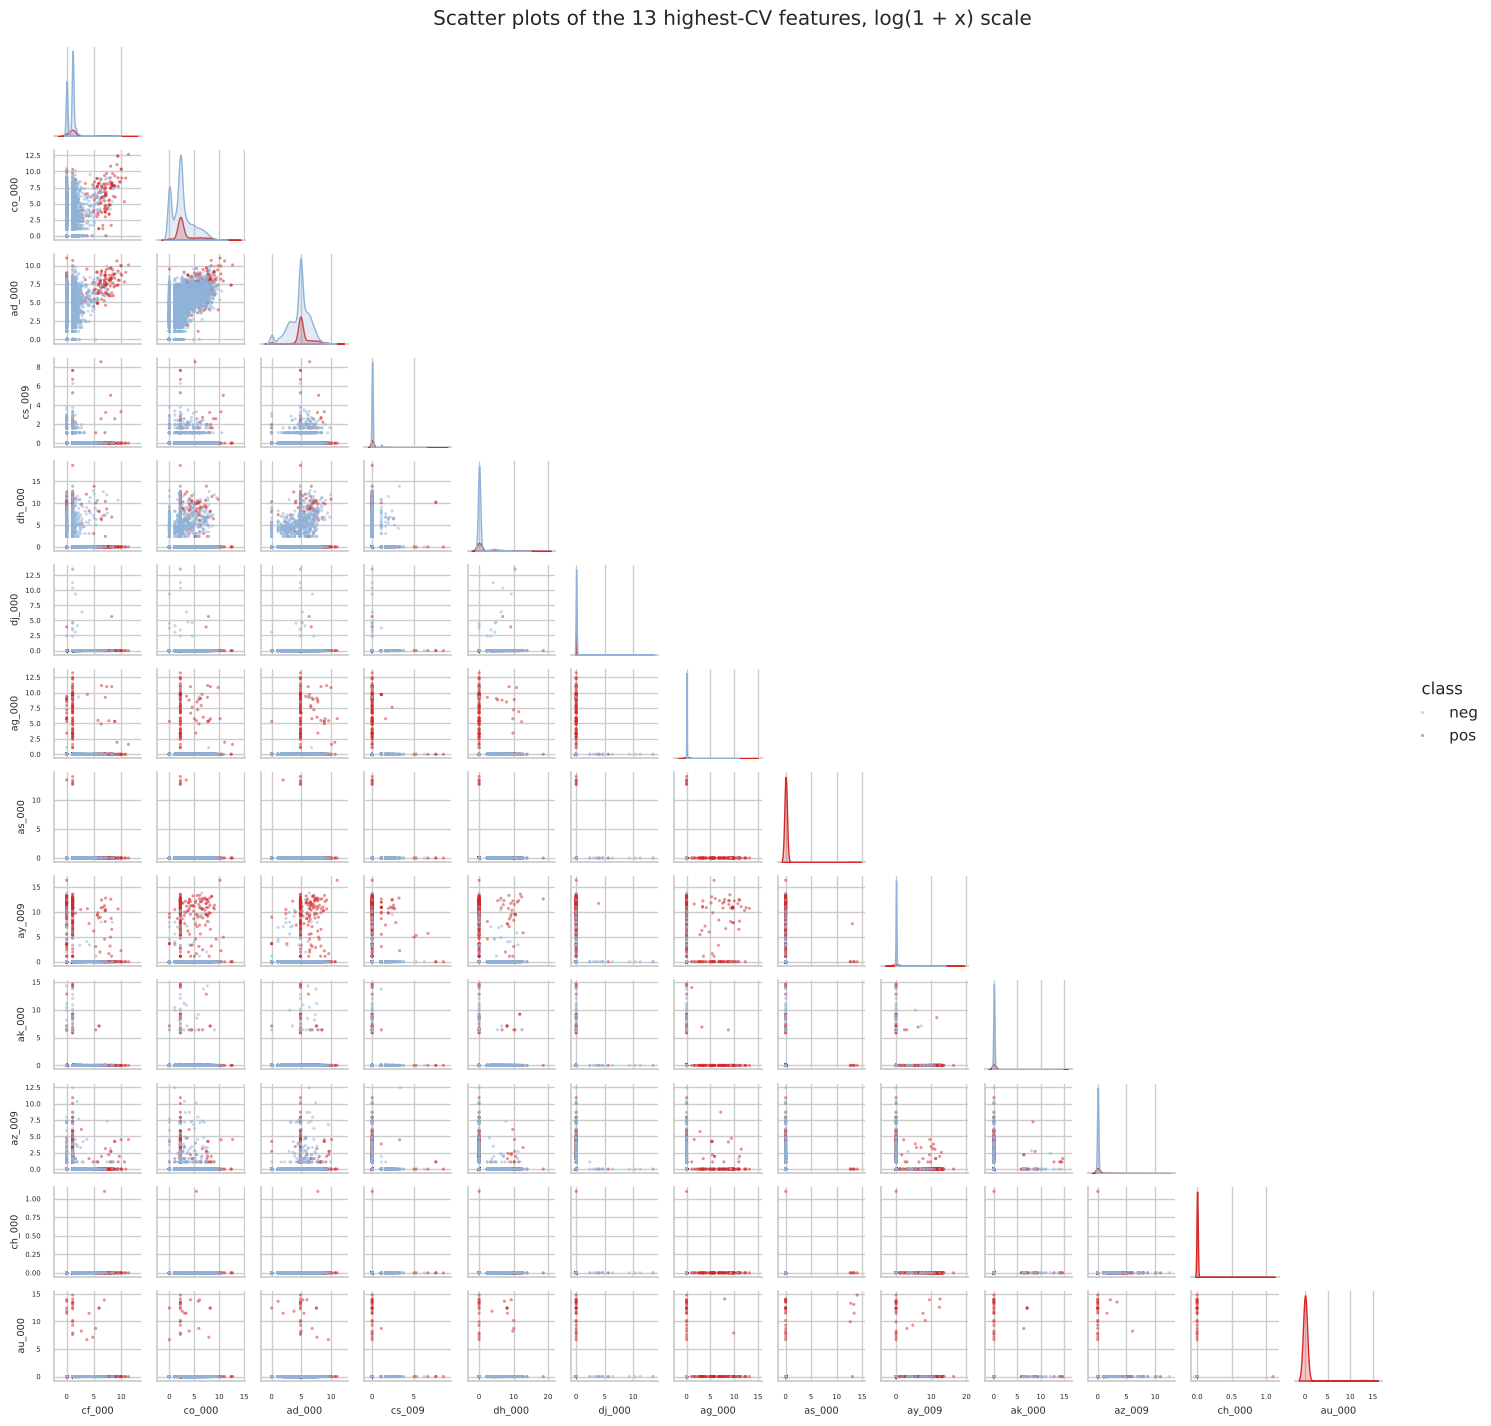

In [ ]:
# Scatter plot matrix coloured by class, as in ISLR Figure 4.1. The features are heavily skewed counts, so they are plotted on a log(1 + x) scale. To keep the plot readable, it shows all 1,000 positive trucks and a random sample of 5,000 negative trucks.
rng = np.random.default_rng(SEED)
idx = np.concatenate([np.where(y_train == 1)[0], rng.choice(np.where(y_train == 0)[0], 5000, replace=False)])
pp = np.log1p(X_train.loc[idx, top_cv])
pp['class'] = np.where(y_train[idx] == 1, 'pos', 'neg')
g = sns.pairplot(pp, hue='class', hue_order=['neg', 'pos'], palette={'neg': '#8fb3d9', 'pos': '#d62728'},
                 corner=True, height=1.1, plot_kws={'s': 4, 'alpha': 0.5, 'edgecolor': None}, diag_kind='kde')
g.figure.suptitle('Scatter plots of the 13 highest-CV features, log(1 + x) scale', y=1.01)
for ax in g.axes.flat:
    if ax is not None:
        ax.xaxis.label.set_size(7); ax.yaxis.label.set_size(7); ax.tick_params(labelsize=5)
plt.show()

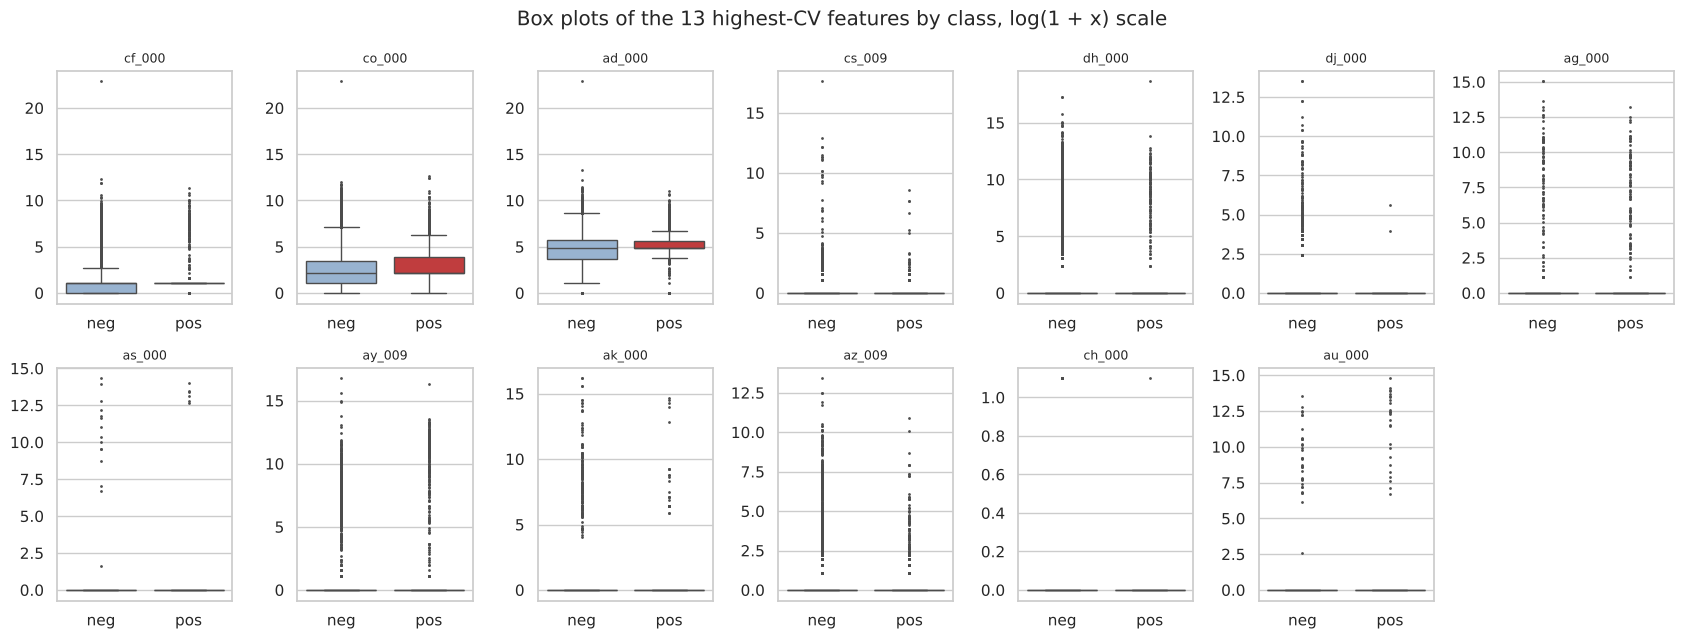

In [9]:
# Box plots of each feature split by class (all 60,000 training trucks), log(1 + x) scale
fig, axes = plt.subplots(2, 7, figsize=(17, 6.5))
for ax, f in zip(axes.flat, top_cv):
    sns.boxplot(x=np.where(y_train == 1, 'pos', 'neg'), y=np.log1p(X_train[f]), order=['neg', 'pos'], ax=ax,
                hue=np.where(y_train == 1, 'pos', 'neg'), palette={'neg': '#8fb3d9', 'pos': '#d62728'},
                legend=False, flierprops={'marker': '.', 'markersize': 2})
    ax.set_title(f, fontsize=9); ax.set_xlabel(''); ax.set_ylabel('')
axes.flat[-1].axis('off')
fig.suptitle('Box plots of the 13 highest-CV features by class, log(1 + x) scale')
plt.tight_layout()
plt.show()

**Can we draw conclusions about significance from the scatter plots? No.**
- **Scatter plots only show marginal, pairwise relationships.** Whether a feature is significant depends on what it adds given the other 169 features, which needs a fitted model and a test (or cross-validated variable importance), not a visual impression. The scatter plot also shows only a sample of the negative trucks.
- **A high CV mostly reflects extreme values and many zeros, not importance.** The top three, `cf_000`, `co_000` and `ad_000` (CV about 244), are driven by a single truck with a value of about $8.6 \times 10^9$, and they are perfectly correlated with each other, so they carry the same information. Most of the other features are zero for nearly every truck (for example, `ch_000` is non-zero for only 10 of the 60,000 trucks), so their means are tiny and their CV is huge. In the box plots, the boxes for most features collapse onto 0 for both classes.
- **Some features suggest a difference, but this is not proof of significance.** Failing trucks are much more often non-zero on some features: `ay_009` (20.7% of positives vs 0.6% of negatives), `az_009` (17.7% vs 2.9%) and `ag_000` (9.7% vs 0.2%). In the scatter plots these appear as red points away from 0. This hints that these features may be useful, but the overlap between the classes is large, and only a model can say whether they matter once the other features are taken into account.

### 1(b)(v) Number of positive and negative data

In [10]:
counts = pd.DataFrame({'train': pd.Series(y_train).value_counts(), 'test': pd.Series(y_test).value_counts()})
counts.index = ['negative', 'positive']
counts.loc['positive share'] = (counts.loc['positive'] / counts.sum()).round(4)
counts

,train,test
negative,59000.0000,15625.0000
positive,1000.0000,375.0000
positive share,0.0167,0.0234


The training set has **59,000 negative and 1,000 positive** trucks (1.67% positive), and the test set has **15,625 negative and 375 positive** trucks (2.34% positive). **Yes, the data set is highly imbalanced:** there are 59 negatives for every positive in the training set. A classifier that always predicts negative would already be 98.3% accurate on the training set, so accuracy alone is a misleading measure here, and the confusion matrix, AUC and total cost are more informative.

## 1(c) Random forest without compensating for class imbalance

A random forest grows many deep trees, each on a bootstrap sample of the training rows and with a random subset of
the features considered at each split, and predicts by majority vote. Each tree leaves out about a third of the
rows; the **out-of-bag (OOB) error** predicts every training row using only the trees that did not see it, which
gives an estimate of the test error without a separate validation set. Below, *misclassification* is the share of
wrongly classified trucks at the default 0.5 threshold.

Random forest (no compensation) | train: AUC = 1.0000   misclassification = 0.00000
          pred neg  pred pos
true neg     59000         0
true pos         0      1000 

Random forest (no compensation) | test: AUC = 0.9944   misclassification = 0.00750
          pred neg  pred pos
true neg     15606        19
true pos       101       274 



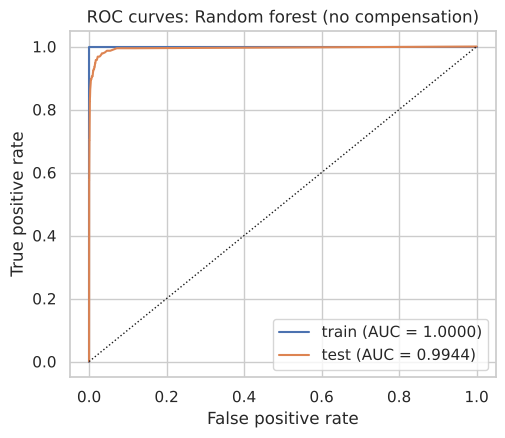

OOB error estimate = 0.00593   test error = 0.00750


In [11]:
rf = RandomForestClassifier(n_estimators=200, oob_score=True, n_jobs=-1, random_state=SEED).fit(X_train, y_train)
res_rf = evaluate('Random forest (no compensation)', rf, X_train, y_train, X_test, y_test)
oob_rf = 1 - rf.oob_score_   # oob_rf: out-of-bag misclassification rate
print(f"OOB error estimate = {oob_rf:.5f}   test error = {res_rf['test']['err']:.5f}")
summary['RF, no compensation'] = res_rf['test']

**Results.** On the training set the forest is perfect (AUC 1.0, no misclassifications), which is expected: fully grown trees memorise their training data, so training error says nothing about generalisation. On the test set, AUC = 0.9944 and misclassification = 0.75%. The confusion matrix shows the effect of the imbalance: only **274 of the 375 failing trucks are caught (101 missed)**, while there are just 19 false alarms. The forest favours the majority class, and with a cost of 500 per missed failure the total cost is 50,690.

**OOB error vs test error.** The OOB error estimate is **0.593%**, close to the test error of **0.750%**, so OOB is a good, cheap estimate of the test error, unlike the training error of 0. It is slightly optimistic, partly because the test set has a higher share of positives (2.34% vs 1.67%), and positives are where the forest makes most of its mistakes.

## 1(d) Random forest compensating for class imbalance

**How class imbalance is addressed in random forests.** A standard random forest minimises the overall error rate, so with only 1.7% positives it tends to favour the majority class. Common remedies (Chen, Liaw and Breiman, 2004):
- **Balanced random forest (undersampling):** grow each tree on a bootstrap sample in which the majority class is undersampled to the size of the minority class, so every tree sees balanced data while the forest as a whole still uses all the negatives.
- **Weighted (cost-sensitive) random forest:** give the minority class a larger weight, inversely proportional to its frequency, in the split criterion and in the leaf votes.
- **Resampling the training data** before fitting, by oversampling the minority class (for example with SMOTE) or undersampling the majority class.
- **Threshold moving:** keep the forest unchanged and lower the probability threshold for predicting the positive class.

I use the **balanced random forest** as the compensated model (`imblearn`'s `BalancedRandomForestClassifier`, 200 trees, each grown on a bootstrap sample of all 1,000 positives and 1,000 randomly chosen negatives), and also report a **class-weighted** forest for comparison.

Balanced random forest | train: AUC = 0.9975   misclassification = 0.05502
          pred neg  pred pos
true neg     55699      3301
true pos         0      1000 

Balanced random forest | test: AUC = 0.9923   misclassification = 0.05194
          pred neg  pred pos
true neg     14800       825
true pos         6       369 



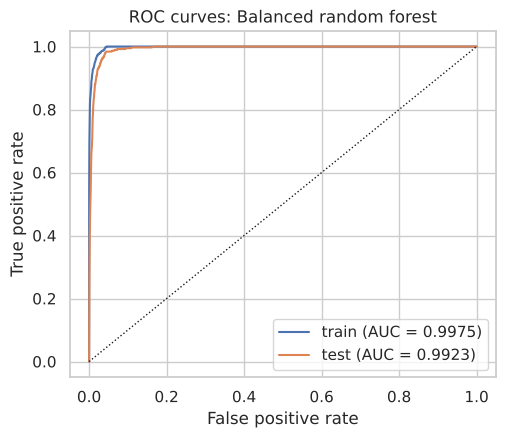

OOB error estimate = 0.04593   test error = 0.05194


In [ ]:
# Balanced random forest: every tree is grown on a bootstrap sample in which the majority class is undersampled to the size of the minority class imblearn prints a generic warning that some inputs have no OOB score; here every training truck does get an out-of-bag prediction (checked: none are missing), so the warning is suppressed.
warnings.filterwarnings('ignore', message='Some inputs do not have OOB scores')
brf = BalancedRandomForestClassifier(n_estimators=200, sampling_strategy='auto', replacement=False, bootstrap=True,
                                     oob_score=True, n_jobs=-1, random_state=SEED).fit(X_train, y_train)
res_brf = evaluate('Balanced random forest', brf, X_train, y_train, X_test, y_test)
oob_brf = 1 - brf.oob_score_
print(f"OOB error estimate = {oob_brf:.5f}   test error = {res_brf['test']['err']:.5f}")
summary['RF, balanced (undersampling)'] = res_brf['test']

In [13]:
# For comparison: cost-sensitive random forest with class weights inversely proportional to class frequency
rf_cw = RandomForestClassifier(n_estimators=200, class_weight='balanced_subsample', oob_score=True,
                               n_jobs=-1, random_state=SEED).fit(X_train, y_train)
p_cw = rf_cw.predict_proba(X_test)[:, 1]
cm_cw = confusion_matrix(y_test, (p_cw >= 0.5).astype(int))
summary['RF, class weights'] = {'cm': cm_cw, 'auc': roc_auc_score(y_test, p_cw), 'err': (cm_cw[0, 1] + cm_cw[1, 0]) / cm_cw.sum()}
print(f"Class-weighted RF: test AUC = {summary['RF, class weights']['auc']:.4f}   test error = {summary['RF, class weights']['err']:.5f}"
      f"   OOB error = {1 - rf_cw.oob_score_:.5f}")
print(pd.DataFrame(cm_cw, index=['true neg', 'true pos'], columns=['pred neg', 'pred pos']).to_string())

Class-weighted RF: test AUC = 0.9931   test error = 0.01069   OOB error = 0.00768
          pred neg  pred pos
true neg     15609        16
true pos       155       220


In [ ]:
# Side-by-side comparison of the random forests on the test set
def compare(names):
    rows = []
    for n in names:
        s = summary[n]; cm = s['cm']
        rows.append({'model': n, 'test AUC': f"{s['auc']:.4f}", 'test error': f"{s['err']:.5f}",
                     'positives caught': f'{cm[1, 1]} of {cm[1].sum()}', 'false alarms': int(cm[0, 1]),
                     'missed failures': int(cm[1, 0]),
                     'total cost': 10 * int(cm[0, 1]) + 500 * int(cm[1, 0])})# cost metric from the data description
    return pd.DataFrame(rows).set_index('model')
compare(['RF, no compensation', 'RF, balanced (undersampling)', 'RF, class weights'])

,test AUC,test error,positives caught,false alarms,missed failures,total cost
model,,,,,,
"RF, no compensation",0.9944,0.00750,274 of 375,19,101,50690
"RF, balanced (undersampling)",0.9923,0.05194,369 of 375,825,6,11250
"RF, class weights",0.9931,0.01069,220 of 375,16,155,77660


**Comparison with 1(c).** The balanced random forest changes the trade-off completely. On the test set it catches **369 of the 375 failing trucks (only 6 missed, versus 101 without compensation)**, at the price of 825 false alarms instead of 19. Its misclassification rate rises from 0.75% to 5.19%, and its AUC is almost unchanged (0.9923 vs 0.9944), because AUC measures ranking, which both forests do well; what changes is where the 0.5 threshold falls. Since a missed failure costs 50 times as much as a false alarm, the total cost drops from 50,690 to **11,250**, a 78% reduction. On the training set it also no longer fits perfectly (misclassification 5.50%, 3,301 false alarms), because each tree sees only 1,000 of the 59,000 negatives.

The OOB error estimate (**4.59%**) is again close to, and slightly below, the test error (**5.19%**).

The **class-weighted** forest barely compensates: it catches only 220 positives, fewer than the uncompensated forest. With fully grown trees, almost every leaf is pure, so reweighting the classes hardly changes the leaf votes. Resampling the data each tree sees, as the balanced forest does, is far more effective for random forests.

**Conclusion:** if the goal is the lowest error rate, the uncompensated forest is best; if the goal is to catch failing trucks, as the cost metric of this data set says it should be, the balanced forest is much better.

## 1(e) XGBoost with an L1 penalty, without compensating for class imbalance

XGBoost builds a sum of shallow trees one at a time, each fitted to the errors (gradients of the logistic loss) of
the trees built so far, so the model's output is a log-odds that passes through the logistic function, as in
logistic regression. `reg_alpha` adds the L1 penalty $\alpha\sum_j |w_j|$ on the leaf weights $w_j$ of every tree.
$\alpha$ is chosen by **5-fold stratified cross-validation** on the training set (stratified folds keep the 1.7%
positive share in every fold), using AUC as the selection criterion because accuracy is uninformative on such
imbalanced data. The other hyperparameters are fixed: 200 trees of depth at most 4 and learning rate 0.1.

**Note on the method.** The question describes a model tree with an L1-penalized logistic regression at each node.
XGBoost, the tool suggested, implements the L1 penalty differently: it penalizes the leaf weights of each tree under
a logistic loss, rather than fitting a separate logistic regression inside each node. It serves the same purpose of
shrinking the model toward simpler fits.

In [ ]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)# skf: 5-fold stratified CV, reused below
alpha_grid = [0, 0.01, 0.1, 1, 10, 100] # alpha_grid: candidate L1 penalties
xgb_base = xgb.XGBClassifier(objective='binary:logistic', n_estimators=200, learning_rate=0.1, max_depth=4,
                             tree_method='hist', eval_metric='logloss', random_state=SEED, n_jobs=-1)
grid_xgb = GridSearchCV(xgb_base, {'reg_alpha': alpha_grid}, cv=skf, scoring={'auc': 'roc_auc', 'acc': 'accuracy'},
                        refit='auc').fit(X_train, y_train)

cvx = pd.DataFrame({'alpha': alpha_grid,
                    'CV AUC': grid_xgb.cv_results_['mean_test_auc'],
                    'CV error': 1 - grid_xgb.cv_results_['mean_test_acc']})
display(cvx.round(5))
best = grid_xgb.best_index_
alpha_xgb = grid_xgb.best_params_['reg_alpha'] # alpha_xgb: alpha with the highest CV AUC
print(f'Chosen alpha = {alpha_xgb}')
print(f"5-fold CV error estimate = {cvx.loc[best, 'CV error']:.5f}   CV AUC = {cvx.loc[best, 'CV AUC']:.4f}")

,alpha,CV AUC,CV error
0,0.00,0.98842,0.00618
1,0.01,0.98871,0.00600
2,0.10,0.98842,0.00612
3,1.00,0.98938,0.00617
4,10.00,0.98939,0.00702
5,100.00,0.98260,0.01135


Chosen alpha = 10
5-fold CV error estimate = 0.00702   CV AUC = 0.9894


XGBoost, L1 (no compensation) | train: AUC = 0.9971   misclassification = 0.00333
          pred neg  pred pos
true neg     58960        40
true pos       160       840 

XGBoost, L1 (no compensation) | test: AUC = 0.9961   misclassification = 0.00813
          pred neg  pred pos
true neg     15599        26
true pos       104       271 



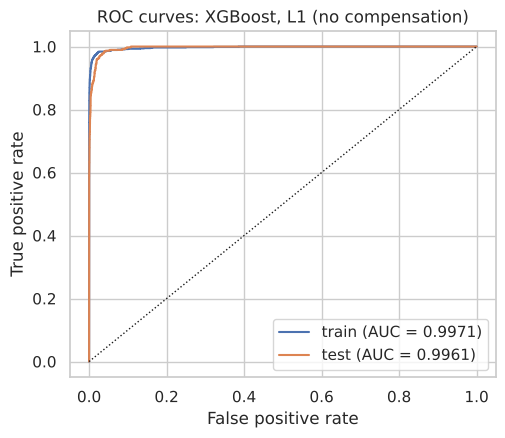

5-fold CV error = 0.00702   test error = 0.00813


In [16]:
res_xgb = evaluate('XGBoost, L1 (no compensation)', grid_xgb.best_estimator_, X_train, y_train, X_test, y_test)
print(f"5-fold CV error = {cvx.loc[best, 'CV error']:.5f}   test error = {res_xgb['test']['err']:.5f}")
summary['XGBoost L1, no compensation'] = res_xgb['test']

**Choice of α.** The CV AUC is nearly flat for $\alpha$ between 0 and 10 (0.9884 to 0.9894) and drops at $\alpha = 100$, where the leaf weights are shrunk too much. The highest CV AUC is at $\alpha = 10$, though it is essentially tied with $\alpha = 1$ (0.98939 vs 0.98938).

**CV error vs test error.** The 5-fold CV error estimate is **0.702%**, and the test error is **0.813%**. The CV estimate is close but slightly optimistic, for the same reason as the OOB estimate in 1(c): the test set has a higher share of positives (2.34% vs 1.67%), and most errors occur on positives.

**Results.** Training: AUC = 0.9971, misclassification = 0.33% (160 of 1,000 positives missed). Test: AUC = 0.9961 (the highest of all the models), misclassification = 0.81%, with **271 of 375 failures caught, 104 missed** and 26 false alarms. The training and test results are close, so boosting with the L1 penalty overfits much less than the fully grown random forest. Like the uncompensated forest, however, it misses more than a quarter of the failing trucks at the 0.5 threshold (total cost 52,260).

## 1(f) XGBoost with an L1 penalty after SMOTE

**SMOTE** (Synthetic Minority Over-sampling Technique) creates new positive examples by taking a positive truck,
choosing one of its 5 nearest positive neighbours, and placing a synthetic point at a random position on the line
segment between them. Here it oversamples the positives until the two classes are the same size.

**The right and wrong way to cross-validate.** SMOTE must be applied **inside** each cross-validation fold, to the
training part only. If SMOTE is applied to the whole training set before splitting, synthetic points built from a
validation fold's positives end up in the training folds, so the model is validated on points almost identical to
ones it was trained on, and the CV estimate becomes overly optimistic. Below, an `imblearn` pipeline runs SMOTE and
then XGBoost, so `GridSearchCV` applies SMOTE only to the training folds (the right way). SMOTE is applied to the
full training set of 60,000 rows, not a downsampled one.

In [ ]:
smote_xgb = ImbPipeline([('smote', SMOTE(random_state=SEED)), ('xgb', xgb_base)])# SMOTE, then XGBoost
grid_sm = GridSearchCV(smote_xgb, {'xgb__reg_alpha': alpha_grid}, cv=skf,
                       scoring={'auc': 'roc_auc', 'acc': 'accuracy'}, refit='auc').fit(X_train, y_train)

cvs = pd.DataFrame({'alpha': alpha_grid,
                    'CV AUC': grid_sm.cv_results_['mean_test_auc'],
                    'CV error': 1 - grid_sm.cv_results_['mean_test_acc']})
display(cvs.round(5))
best_sm = grid_sm.best_index_
alpha_sm = grid_sm.best_params_['xgb__reg_alpha']
print(f'Chosen alpha = {alpha_sm}')
print(f"5-fold CV error estimate (SMOTE inside the folds) = {cvs.loc[best_sm, 'CV error']:.5f}   CV AUC = {cvs.loc[best_sm, 'CV AUC']:.4f}")

,alpha,CV AUC,CV error
0,0.00,0.98732,0.00952
1,0.01,0.98797,0.00932
2,0.10,0.98741,0.00913
3,1.00,0.98678,0.00920
4,10.00,0.98750,0.01038
5,100.00,0.98503,0.01865


Chosen alpha = 0.01
5-fold CV error estimate (SMOTE inside the folds) = 0.00932   CV AUC = 0.9880


XGBoost, L1 + SMOTE | train: AUC = 0.9989   misclassification = 0.00465
          pred neg  pred pos
true neg     58775       225
true pos        54       946 



XGBoost, L1 + SMOTE | test: AUC = 0.9932   misclassification = 0.01238
          pred neg  pred pos
true neg     15468       157
true pos        41       334 



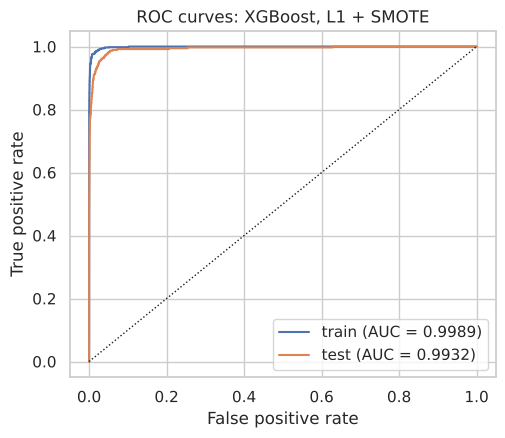

5-fold CV error = 0.00932   test error = 0.01238


In [18]:
# The final model is the pipeline refitted on the full training set (SMOTE applied to all 60,000 rows).
# Training metrics are computed on the original training data, not on the synthetic points.
res_sm = evaluate('XGBoost, L1 + SMOTE', grid_sm.best_estimator_, X_train, y_train, X_test, y_test)
print(f"5-fold CV error = {cvs.loc[best_sm, 'CV error']:.5f}   test error = {res_sm['test']['err']:.5f}")
summary['XGBoost L1 + SMOTE'] = res_sm['test']

In [19]:
# The wrong way, for comparison: SMOTE applied to the whole training set first, then cross-validated
X_sm, y_sm = SMOTE(random_state=SEED).fit_resample(X_train, y_train)
wrong = cross_validate(xgb_base.set_params(reg_alpha=alpha_sm), X_sm, y_sm, cv=skf, scoring={'auc': 'roc_auc', 'acc': 'accuracy'})
print(f'Rows after SMOTE on the full training set: {len(y_sm)} ({int(y_sm.sum())} positive)')
print(f"Wrong way:  CV AUC = {wrong['test_auc'].mean():.4f}   CV error = {1 - wrong['test_acc'].mean():.5f}")
print(f"Right way:  CV AUC = {cvs.loc[best_sm, 'CV AUC']:.4f}   CV error = {cvs.loc[best_sm, 'CV error']:.5f}")
print(f"Test set:   AUC = {res_sm['test']['auc']:.4f}   error = {res_sm['test']['err']:.5f}")

Rows after SMOTE on the full training set: 118000 (59000 positive)
Wrong way:  CV AUC = 0.9998   CV error = 0.00449
Right way:  CV AUC = 0.9880   CV error = 0.00932
Test set:   AUC = 0.9932   error = 0.01238


In [20]:
compare(['XGBoost L1, no compensation', 'XGBoost L1 + SMOTE'])

,test AUC,test error,positives caught,false alarms,missed failures,total cost
model,,,,,,
"XGBoost L1, no compensation",0.9961,0.00813,271 of 375,26,104,52260
XGBoost L1 + SMOTE,0.9932,0.01238,334 of 375,157,41,22070


**Choice of α.** With SMOTE inside the folds, the CV AUC is again nearly flat for small $\alpha$, and the best value is $\alpha = 0.01$ (CV AUC 0.9880).

**Right vs wrong way of cross-validating.** Done the right way, the 5-fold CV error estimate is **0.932%**, against a test error of **1.238%**. Done the wrong way, by applying SMOTE to the whole training set before splitting, the CV estimate is **0.449%** with a CV AUC of **0.9998**, which is far too optimistic: the test AUC is only 0.9932. The wrong way leaks information, because synthetic positives created from a validation fold's positives sit in the training folds, so the model is validated on points almost identical to ones it was trained on. (The wrong-way error is also measured on balanced data, which is not the class mix the model faces in practice.)

**Comparison of the uncompensated and SMOTE models.**
- **Failures caught:** SMOTE catches **334 of the 375 failing trucks (41 missed)** instead of 271 (104 missed).
- **False alarms:** they rise from 26 to 157.
- **Error rate and AUC:** the misclassification rate rises from 0.81% to 1.24%, and the test AUC falls slightly (0.9932 vs 0.9961). The ranking of trucks is about as good; SMOTE mainly moves the decision boundary toward the minority class.
- **Total cost:** it drops from 52,260 to **22,070**, a 58% reduction.
- **Training metrics:** on the original training data, SMOTE gives AUC 0.9989 and 0.47% misclassification, with only 54 positives missed.

So, as with the balanced random forest, compensating for the imbalance trades a slightly higher overall error for many more failures detected, which is what matters for this problem. SMOTE is a more moderate correction than the balanced forest: fewer false alarms (157 vs 825), but more missed failures (41 vs 6).

## Summary of all models on the test set

In [21]:
compare(list(summary.keys()))

,test AUC,test error,positives caught,false alarms,missed failures,total cost
model,,,,,,
"RF, no compensation",0.9944,0.00750,274 of 375,19,101,50690
"RF, balanced (undersampling)",0.9923,0.05194,369 of 375,825,6,11250
"RF, class weights",0.9931,0.01069,220 of 375,16,155,77660
"XGBoost L1, no compensation",0.9961,0.00813,271 of 375,26,104,52260
XGBoost L1 + SMOTE,0.9932,0.01238,334 of 375,157,41,22070


**Conclusion.** Without compensation, both the random forest and XGBoost reach very low error rates (0.75% and 0.81%) and high AUCs (0.994 and 0.996, the best), but both miss over a quarter of the failing trucks, because the 1:59 imbalance pushes predictions toward the negative class. Compensating for the imbalance raises the error rate but catches far more failures: the balanced random forest misses only 6 of 375 and has the lowest total cost (11,250), and SMOTE with XGBoost misses 41 with fewer false alarms (cost 22,070). Class weights alone do not help fully grown random forests. Which model is best depends on the goal: for overall accuracy, the uncompensated models; for detecting APS failures under the cost metric of this data set, the compensated ones, with the balanced random forest best here.

# 2. ISLR 6.6.3

The lasso estimates minimize $\sum_{i=1}^n \left(y_i - \beta_0 - \sum_{j=1}^p \beta_j x_{ij}\right)^2$ subject to $\sum_{j=1}^p |\beta_j| \le s$. As $s$ increases from 0, the constraint loosens: at $s = 0$ every $\beta_j$ is 0 (only the intercept is fitted), and for large enough $s$ the constraint no longer binds and the solution is the least-squares fit.

**(a) Training RSS: (iv) steadily decreases.** A larger $s$ enlarges the set of allowed coefficients, so the minimum training RSS over that set can only go down, from the null model at $s = 0$ to the least-squares RSS.

**(b) Test RSS: (ii) decreases initially, and then eventually starts increasing in a U shape.** At first, the extra flexibility lets the model capture the real signal, so test error falls. Once $s$ is large, the model starts fitting noise in the training data, and test error rises again.

**(c) Variance: (iii) steadily increases.** At $s = 0$ the fit is a constant and has almost no variance. As $s$ grows, the coefficients depend more and more on the particular training sample, so the variance rises.

**(d) Squared bias: (iv) steadily decreases.** A small $s$ forces the coefficients toward zero, which biases the fit. As $s$ grows, the model becomes more flexible and closer to least squares, so the bias falls.

**(e) Irreducible error: (v) remains constant.** The irreducible error $\text{Var}(\epsilon)$ comes from the noise in the response, not from the model, so it does not depend on $s$.

# 3. ISLR 6.6.5

We have $n = p = 2$, with $x_{11} = x_{12}$, $x_{21} = x_{22}$, $y_1 + y_2 = 0$, $x_{11} + x_{21} = 0$ and $x_{12} + x_{22} = 0$, so the intercept is $\hat\beta_0 = 0$. To simplify, write $x_{11} = x_{12} = a$, which gives $x_{21} = x_{22} = -a$, and $y_2 = -y_1$.

**(a) Ridge optimization problem.**
$$\min_{\beta_1, \beta_2}\; (y_1 - \beta_1 x_{11} - \beta_2 x_{12})^2 + (y_2 - \beta_1 x_{21} - \beta_2 x_{22})^2 + \lambda(\beta_1^2 + \beta_2^2)$$
Substituting the values above, both residuals become $\pm\,(y_1 - a(\beta_1 + \beta_2))$, so the problem is
$$\min_{\beta_1, \beta_2}\; 2\big(y_1 - a(\beta_1 + \beta_2)\big)^2 + \lambda(\beta_1^2 + \beta_2^2).$$

**(b) The ridge estimates satisfy $\hat\beta_1 = \hat\beta_2$.** The objective is differentiable, so we set both partial derivatives to zero:
$$\frac{\partial}{\partial \beta_1}: \; -4a\big(y_1 - a(\beta_1 + \beta_2)\big) + 2\lambda\beta_1 = 0$$
$$\frac{\partial}{\partial \beta_2}: \; -4a\big(y_1 - a(\beta_1 + \beta_2)\big) + 2\lambda\beta_2 = 0$$
The first terms are identical, so subtracting the two equations gives $2\lambda(\beta_1 - \beta_2) = 0$. Since $\lambda > 0$, $\hat\beta_1 = \hat\beta_2$. (Solving gives $\hat\beta_1 = \hat\beta_2 = \dfrac{2a\,y_1}{4a^2 + \lambda}$.) Intuitively, the two predictors are identical, so the RSS only depends on $\beta_1 + \beta_2$, and the ridge penalty $\beta_1^2 + \beta_2^2$ is smallest for a given sum when the two are equal.

**(c) Lasso optimization problem.**
$$\min_{\beta_1, \beta_2}\; (y_1 - \beta_1 x_{11} - \beta_2 x_{12})^2 + (y_2 - \beta_1 x_{21} - \beta_2 x_{22})^2 + \lambda(|\beta_1| + |\beta_2|),$$
which, with the values above, is $\min_{\beta_1, \beta_2}\; 2\big(y_1 - a(\beta_1 + \beta_2)\big)^2 + \lambda(|\beta_1| + |\beta_2|)$.

**(d) The lasso coefficients are not unique.** Again the RSS depends only on $t = \beta_1 + \beta_2$. For a fixed $t$, the penalty satisfies $|\beta_1| + |\beta_2| \ge |t|$, with equality exactly when $\beta_1$ and $\beta_2$ have the same sign (or one is zero). So the problem reduces to choosing $t$ to minimize $2(y_1 - a t)^2 + \lambda|t|$, which gives a single value $\hat t$ (for $a y_1 > 0$, $\hat t = \max\!\left(\dfrac{y_1}{a} - \dfrac{\lambda}{4a^2},\, 0\right)$). Then **every** pair with $\hat\beta_1 + \hat\beta_2 = \hat t$ and $\hat\beta_1, \hat\beta_2 \ge 0$ gives the same, minimal objective value. The solutions form a line segment, from $(\hat t, 0)$ to $(0, \hat t)$.

Geometrically, in the constrained form $|\beta_1| + |\beta_2| \le s$, the RSS contours are straight lines $\beta_1 + \beta_2 = \text{constant}$, which are parallel to the edge of the diamond-shaped constraint region in the first quadrant (or the third, if $\hat t < 0$). The best contour touches the diamond along that whole edge, $\beta_1 + \beta_2 = s$, instead of at a single corner.

# 4. ISLR 8.4.5

The ten bootstrapped estimates of $P(\text{Class is Red} \mid X)$ are 0.1, 0.15, 0.2, 0.2, 0.55, 0.6, 0.6, 0.65, 0.7 and 0.75. Each tree classifies $X$ as Red when its estimate is above 0.5.

In [ ]:
p_red = np.array([0.1, 0.15, 0.2, 0.2, 0.55, 0.6, 0.6, 0.65, 0.7, 0.75])# P(Red | X) from 10 bootstrap trees
votes_red = int((p_red > 0.5).sum())
print(f'Majority vote: {votes_red} of 10 trees predict Red  ->  {"Red" if votes_red > 5 else "Green"}')
print(f'Average probability: {p_red.mean():.2f}  ->  {"Red" if p_red.mean() > 0.5 else "Green"}')

Majority vote: 6 of 10 trees predict Red  ->  Red
Average probability: 0.45  ->  Green


**Majority vote: Red.** Six of the ten trees (0.55, 0.6, 0.6, 0.65, 0.7, 0.75) have a probability above 0.5 and vote Red, against four votes for Green, so the majority-vote prediction is **Red**.

**Average probability: Green.** The average of the ten estimates is $4.5 / 10 = 0.45 < 0.5$, so the prediction based on the average probability is **Green**.

The two approaches disagree because the four Green votes are very confident (0.1 to 0.2) while the six Red votes are only moderately confident (0.55 to 0.75).

# 5. ISLR 9.7.3

The seven observations are: Red at (3, 4), (2, 2), (4, 4) and (1, 4); Blue at (2, 1), (4, 3) and (4, 1). The plots below show parts (a), (b) to (g), and (h).

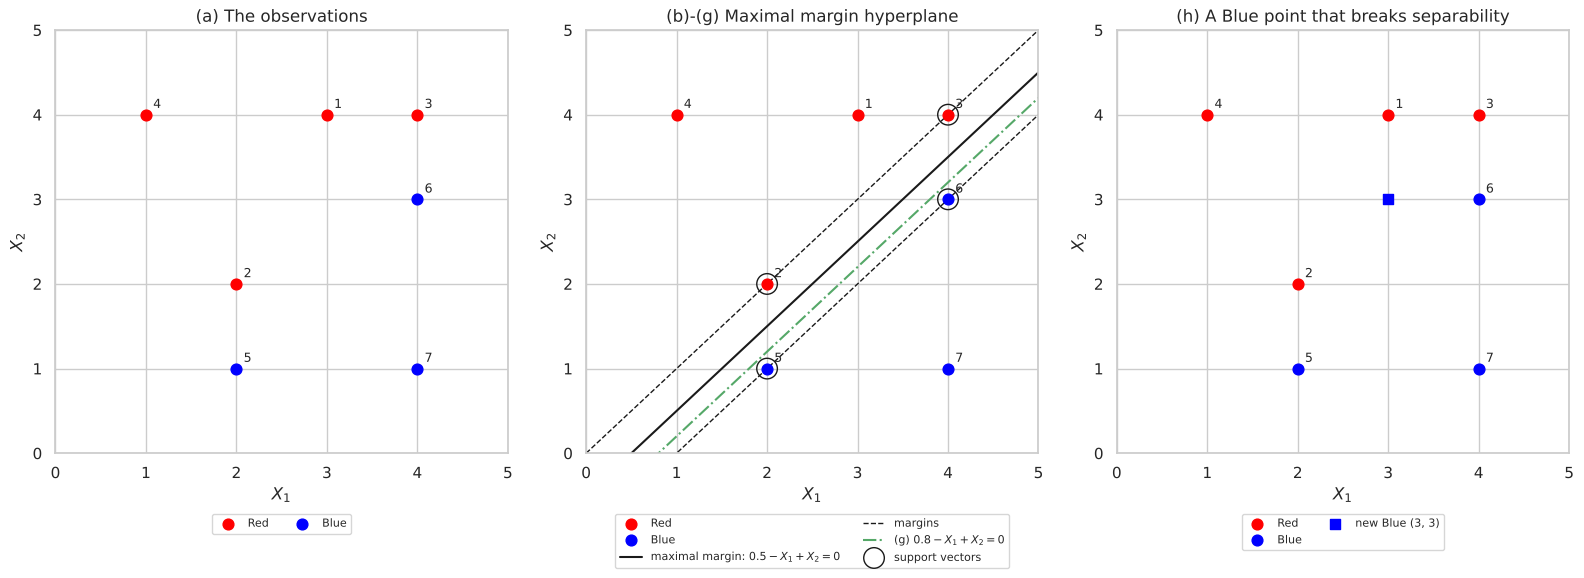

In [23]:
pts = pd.DataFrame({'X1': [3, 2, 4, 1, 2, 4, 4], 'X2': [4, 2, 4, 4, 1, 3, 1],
                    'Y': ['Red', 'Red', 'Red', 'Red', 'Blue', 'Blue', 'Blue']}, index=range(1, 8))
x = np.linspace(0, 5, 50)
fig, axes = plt.subplots(1, 3, figsize=(16, 6))
titles = ['(a) The observations', '(b)-(g) Maximal margin hyperplane', '(h) A Blue point that breaks separability']
for ax, title in zip(axes, titles):
    for lab, col in [('Red', 'red'), ('Blue', 'blue')]:
        s = pts[pts.Y == lab]
        ax.scatter(s.X1, s.X2, c=col, s=60, label=lab, zorder=3)
    for i, r in pts.iterrows():
        ax.annotate(str(i), (r.X1 + 0.08, r.X2 + 0.08), fontsize=9)
    ax.set_xlim(0, 5); ax.set_ylim(0, 5); ax.set_xlabel('$X_1$'); ax.set_ylabel('$X_2$'); ax.set_title(title)
# (b) hyperplane 0.5 - X1 + X2 = 0, margins X2 = X1 and X2 = X1 - 1; (g) a non-optimal hyperplane 0.8 - X1 + X2 = 0
axes[1].plot(x, x - 0.5, 'k-', label='maximal margin: $0.5 - X_1 + X_2 = 0$')
axes[1].plot(x, x, 'k--', lw=1, label='margins')
axes[1].plot(x, x - 1, 'k--', lw=1)
axes[1].plot(x, x - 0.8, 'g-.', label='(g) $0.8 - X_1 + X_2 = 0$')
sv = pts.loc[[2, 3, 5, 6]]
axes[1].scatter(sv.X1, sv.X2, s=220, facecolors='none', edgecolors='k', label='support vectors', zorder=4)
axes[2].scatter([3], [3], c='blue', s=60, marker='s', zorder=3, label='new Blue (3, 3)')
for ax in axes:
    ax.legend(fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.13), ncol=2)
plt.tight_layout()
plt.show()

**(a)** The left plot shows the seven observations. The Red points lie above the Blue points, along a diagonal direction.

**(b) Maximal margin hyperplane.** The closest pairs across the two classes are Red (2, 2) and Blue (2, 1), and Red (4, 4) and Blue (4, 3). The maximal margin hyperplane passes halfway between them, through (2, 1.5) and (4, 3.5). Its slope is $(3.5 - 1.5)/(4 - 2) = 1$, so the line is $X_2 = X_1 - 0.5$, that is
$$0.5 - X_1 + X_2 = 0.$$
It is drawn as the solid black line in the middle plot.

**(c) Classification rule.** Classify to **Red if $0.5 - X_1 + X_2 > 0$**, and to **Blue otherwise**. So $\beta_0 = 0.5$, $\beta_1 = -1$ and $\beta_2 = 1$. (Check: Red (3, 4) gives $0.5 - 3 + 4 = 1.5 > 0$, and Blue (4, 1) gives $0.5 - 4 + 1 = -2.5 < 0$.)

**(d) The margin.** The margins are the parallel lines through the support vectors, $X_2 = X_1$ (through the Red support vectors) and $X_2 = X_1 - 1$ (through the Blue ones), drawn as dashed lines. The margin is the distance from the hyperplane to either of them, for example from (2, 2):
$$M = \frac{|0.5 - 2 + 2|}{\sqrt{(-1)^2 + 1^2}} = \frac{0.5}{\sqrt 2} \approx 0.354.$$

**(e) Support vectors.** Observations 2, 3, 5 and 6: Red (2, 2) and (4, 4), and Blue (2, 1) and (4, 3). They are circled in the middle plot.

**(f)** Observation 7, Blue (4, 1), is not a support vector: it lies well outside the margin, at distance $2.5/\sqrt 2 \approx 1.77$ from the hyperplane. The maximal margin hyperplane depends only on the support vectors, so a slight movement of observation 7 (that keeps it outside the margin) would not change the hyperplane.

**(g) A separating hyperplane that is not optimal:** $0.8 - X_1 + X_2 = 0$ (the green dash-dot line). It still separates the classes, since every Red point gives at least 0.8 and every Blue point at most $-0.2$, but it is closer to the Blue points than to the Red ones, so its margin ($0.2/\sqrt 2 \approx 0.14$) is smaller than the maximal margin.

**(h)** Add a **Blue observation at (3, 3)** (right plot). It lies exactly midway between the Red points (2, 2) and (4, 4). Any line that puts (2, 2) and (4, 4) on the Red side also puts every point on the segment between them, including (3, 3), on the Red side, because each side of a line is convex. So no hyperplane can separate the two classes.